In [56]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("../data/raw/bank-additional-full.csv",sep=";")

In [57]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

In [65]:
df.columns
diff = df[['age','job','housing','poutcome','y']]
X = diff.drop('y',axis=1)
y = diff['y']

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y,shuffle=True
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.1765,
    random_state=42,
    stratify=y_train_val
)
numeric_featrues=['age']
categorical_featrues=['job','housing','poutcome']

In [59]:
numeric_pipe = Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="constant")),
    ("encoder",OneHotEncoder(handle_unknown='ignore'))
])

In [ ]:
preprocces = ColumnTransformer(
    transformers=[("num",numeric_pipe,numeric_featrues),
                  ("cat",categorical_pipeline,categorical_featrues)],
)


Name of algorithm :
Logistic Regression


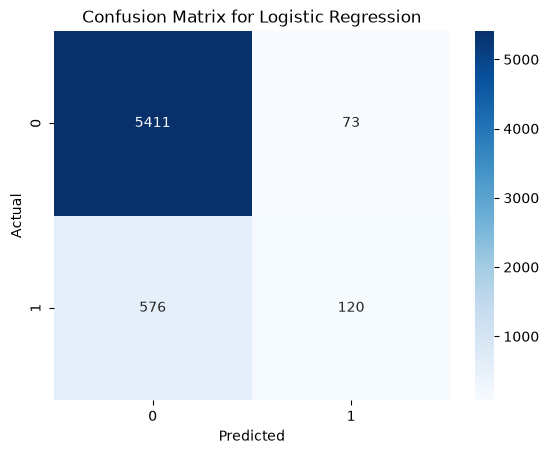

Name of algorithm :
Random Forest


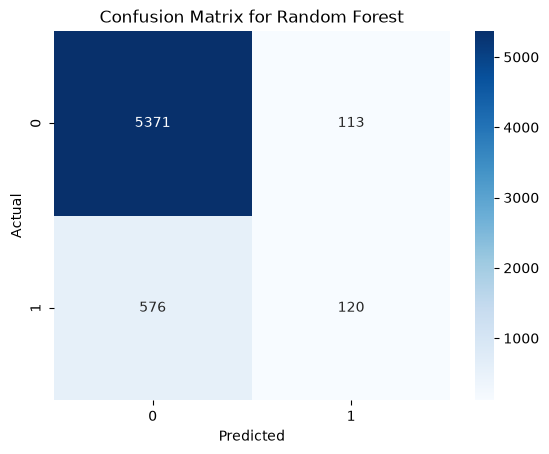

Name of algorithm :
Gradient Boosting


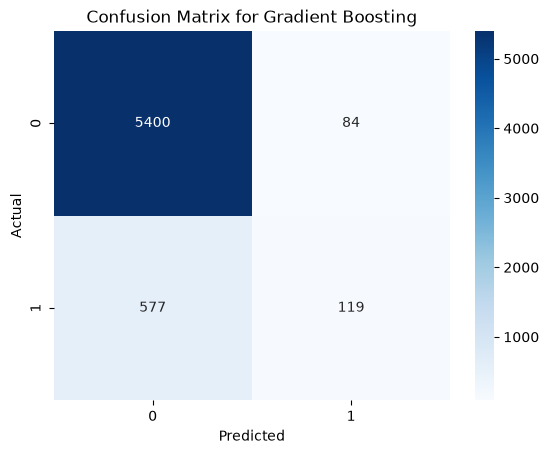

Name of algorithm :
Decision Tree


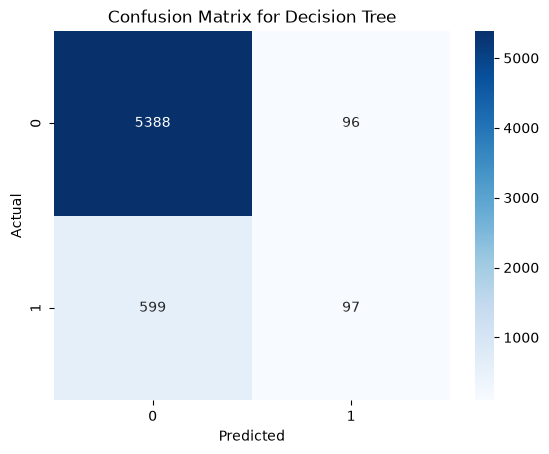

        Logistic Regression  Random Forest  Gradient Boosting  Decision Tree
prec               0.621762       0.515021           0.586207       0.502591
f1                 0.269966       0.258342           0.264739       0.218223
recall             0.172414       0.172414           0.170977       0.139368


In [63]:

from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import classification_report,confusion_matrix
from sklearn.tree import DecisionTreeClassifier
import seaborn as sns
import matplotlib.pyplot as plt

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42)
}

result = pd.DataFrame()

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor",preprocces),
        ("model",model)
        ])
    
    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_val)

    cm=classification_report(y_val,y_pred,output_dict=True)['yes']
    

    

    
    print("Name of algorithm :")
    print(name)
    cm1 = confusion_matrix(y_val,y_pred)
    sns.heatmap(cm1, annot=True, fmt='d', cmap='Blues')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix for '+name)
    plt.show()

    result[name] ={
        "prec" : cm["precision"],
        "f1" : cm["f1-score"],
        "recall" : cm["recall"]
    }
    
print(result)